Module 1 — State Management Fundamentals in Python

Our objective is to understand five things:
1. What constitutes state in a program?
2. How is state created, accessed, and updated?
3. Mutable vs immutable state — why does it matter?
4. How does state pass between functions or agents?
5. How would you explain these concepts in an interview?


1. State is more than just a variable
Consider a document retrieval workflow:

In [1]:
state = {
    "query": "Sweden contractor leave policy",
    "status": "pending",
    "documents": [],
    "retry_count": 0
}

All four fields represent aspects of the workflow's current state.

Field	    What it represents
query	    Input/context
status	    Execution progress
documents	Intermediate results
retry_count	Recovery information

Key distinction: 
    A variable holds a value. State is the collection of information describing the system's condition at a particular moment.

State can be held in variables, objects, dictionaries, databases, or distributed stores.

2. Worked example 1 - Mutable state 

In [4]:
state = {
    "status": "pending", 
    "documents": []
    }

def retrieve(state):
    state["documents"].append("policy_2026.pdf)")
    state["status"]= "completed"

retrieve(state)
print (state)

{'status': 'completed', 'documents': ['policy_2026.pdf)']}


Python dictionaries and lists are mutable. When passed to a function, the function receives a reference to the same object.

Question: What is the downside of updating shared mutable state directly?
Answer: Other parts of the application can observe unexpected changes. 
This can make debugging, testing, concurrency, and tracking state transitions more difficult.

3. Worked example 2 — Creating a new state

In [6]:
state = {
    "status": "pending",
    "documents": []
}

def retrieve(state):
    return {
        **state,
        "status": "completed",
        "documents": ["Policy_2026.pdf"]
    }

new_state = retrieve(state)

print(state["status"])      # pending
print(new_state["status"])  # completed

pending
completed


Why is this useful?
In a multi-step agent workflow, it becomes easier to reason about explicit transitions:

State S0 (status = pending)
|
retrueve (S0) 
|
State S1 (status = completed)

This is conceptually similar to how a workflow engine coordinates state transitions.
However, returning a new dictionary does not automatically make a system thread-safe or guarantee durable state history.


4. Worked example 3 — Passing state across agent steps

Here is a deliberately small agent-like workflow.

In [8]:
def planner(state):
    return {**state, "plan": "Retrieve policy"}

def researcher(state):
    return {**state, "docs": ["Policy 2026"]}

def summarizer(state):
    return {**state, "answer": f"Found {state['docs'][0]}"}

state = {"query": "Sweden leave policy"}

state = planner(state)
state = researcher(state)
state = summarizer(state)

print(state)
print (state["plan"])
print (state["answer"])


{'query': 'Sweden leave policy', 'plan': 'Retrieve policy', 'docs': ['Policy 2026'], 'answer': 'Found Policy 2026'}
Retrieve policy
Found Policy 2026


There are three interesting points here:

- Every function receives the existing workflow context.
- Each function contributes a new field without discarding existing fields.
- Subsequent functions depend on state produced by previous steps.

This is the foundational idea behind stateful multi-step agent orchestration.

In LangGraph, for example, nodes can return partial state updates that the framework merges according to the state schema and configured reducers.

Exercise: A workflow begins with a document awaiting processing. Write a function called process_document(state) that returns an updated state without modifying the original dictionary.


Refer to the below notebook for the solution:  "track agent state change.ipynb"

### Some important Questions

1. If one agent changes the shared state, will other agents automatically see the change?

Only if they access the same mutable state or receive the updated state through orchestration. Separate processes do not automaticallly share python memory. In a distributed system, state must be explicitly communicated or persisted. 

2. What is the difference between state management and state persistence?
State management controls how information changes during execution. State persistence saves information durably, typicaly in a database or checkpoint store, so it can survice failure or restarts. 

Summary 
State management is how a system maintains, updates, and coordinates information across execution steps. In agentic workflows, each agent reads the relevant context, performs its task, and returns updates that influence subsequent execution. Explicit state transitions improve predictability, debugging, testing, and recovery.

### Module 2 - Asynchronous State and Concurrency 

1. Why is concurrentcy a problem for state management?

Imagine you have two AI agents working simultaneously:
    * Agent A rerieves policy documents. 
    * Agent B retrieves employee information. 
    * Both need to update the same workflow state. 

The challenge isn't simlpy that theu run simultaneously. Its what happens when they both read and modify shared information. 

In [10]:
# Example: Two Agents updating the same counter

import asyncio 

state = {"completed_tasks": 0}

async def agent(name):
    count = state["completed_tasks"]

    await asyncio.sleep(0.1)
    state["completed_tasks"] = count + 1 

async def main(): 
    await asyncio.gather(
        agent("Research"),
        agent("Validation")
    )
    print (state)

await main()

{'completed_tasks': 1}


Expected Result: 
{'completed_tasks': 2}

Two agents completing their tasks, so the count should be two. But the answer is 1. 

Why ? Because, both coroutines read the counter before either updates it.. i.e. Lost Update 

Agent A                                     Agent B 
Read Coutner = 0                            Read Counter = 0 
Await I/O                                   Await I/O
Write Counter = 1                           Write Counter = 1 

So, Final Counter = 1, (xpected=2)
One update is Lost ... 

This is called RACE CONDITION!!!

The result depends on the order in which concurrent operations access shared state.

Important Python detail: In this example, the await allows the coroutine to suspend between reading and writing. The fact that asyncio normally uses one thread does not automatically prevent race conditions.

**Solution A - Use asyncio.Lock**

**Solution B - Isolated agent state and merging**

**Solution A - Use asyncio.Lock**

In [12]:
import asyncio
state = {"completed_tasks": 0}
lock = asyncio.Lock()

async def agent(name):
    async with lock: 
        count = state["completed_tasks"]
        await asyncio.sleep(0.1)
        state["completed_tasks"] = count + 1

async def main():
    await asyncio.gather(
        agent("Research"),
        agent("Validation")
    )
    print (state)

await main()

{'completed_tasks': 2}


This lock ensures only one coroutine at a time can execute the protected critical section

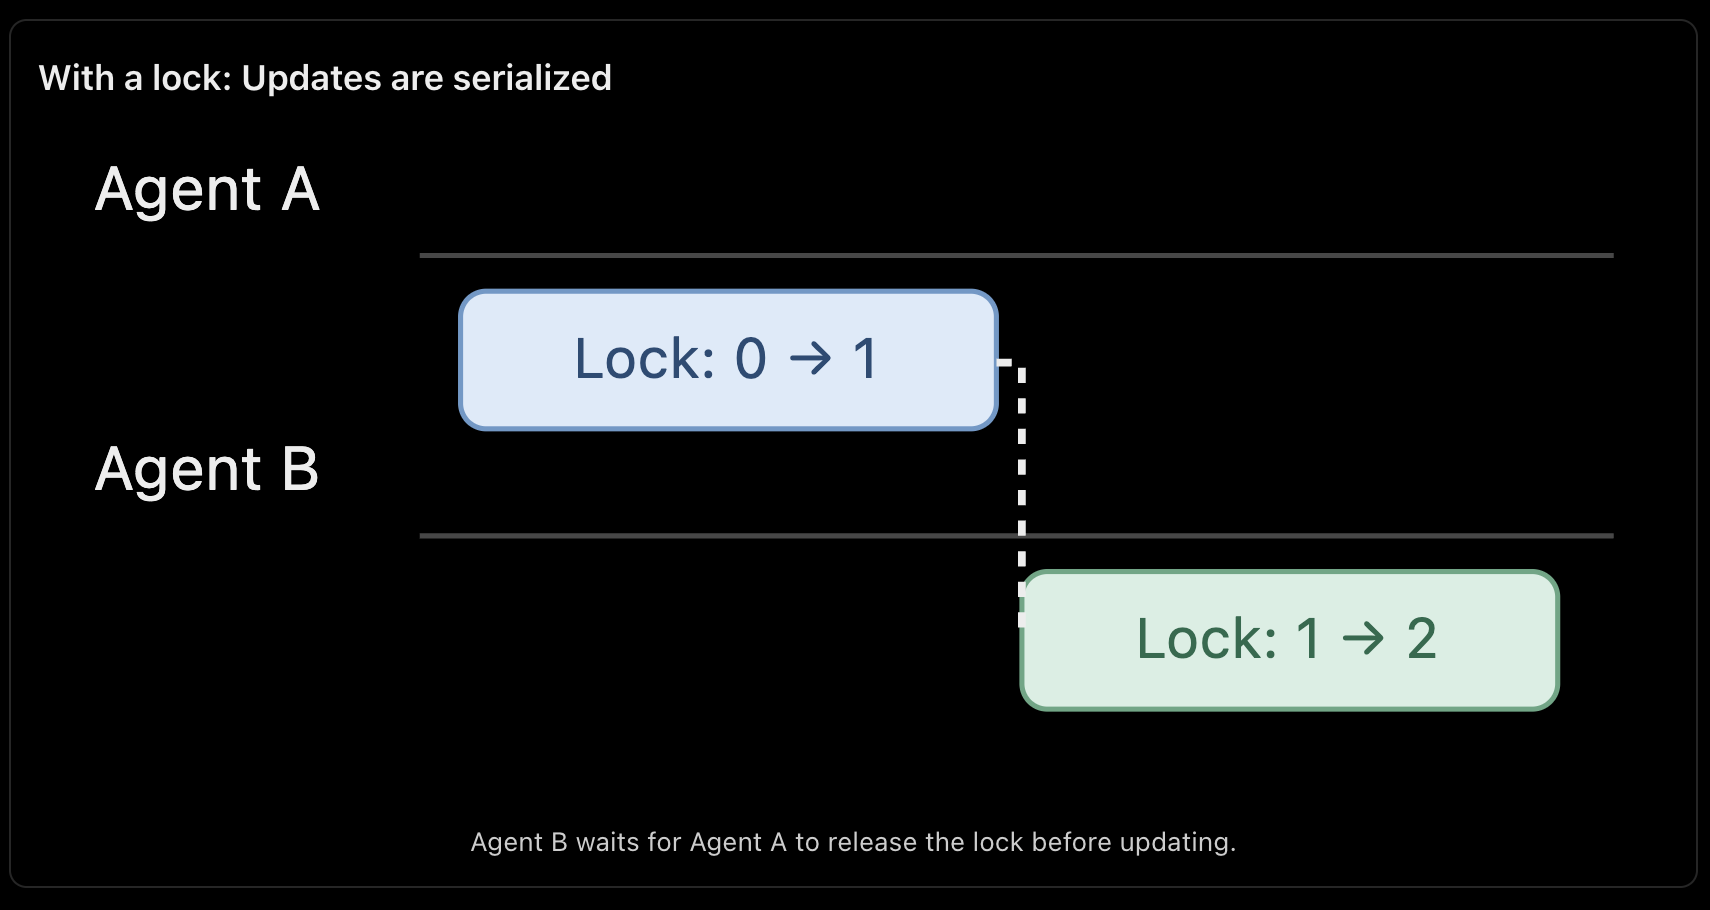

Question: 
Are locks always the best solution ?

No. Locks can reduce concurrency. 

Furthermore, asyncio.Lock only coordinates coroutines sharing that lock within the same event loop. 

In a distributed agent system running across multiple workers or containers, you need stronger coordination mechanisms such as database transactions, optimistic locking, or distributed coordination.

Also, avoid holding a lock during slow network calls when you can safely keep the critical section smaller.

**Solution B - Isolated agent state and merging**
This is particularly relevant to multi-agent workflows.

Instead of letting both agents modify the same dictionary, have them produce independent updates.

In [22]:
import asyncio

async def research_agent():
    await asyncio.sleep(0.1)
    return {"documents": ["Policy_2026.pdf"]}

async def validation_agent():
    await asyncio.sleep(0.1)
    return {"validated": True}

async def main():
    res = await asyncio.gather(
        research_agent(),
        validation_agent()
    )

    state = {"query": "Sweden leave policy"}

    for update in res:
        state.update(update)

    print(state)

await main()


{'query': 'Sweden leave policy', 'documents': ['Policy_2026.pdf'], 'validated': True}


Here, the agents do not modify a shared object directly. They return independent updates, which are merged afterward.

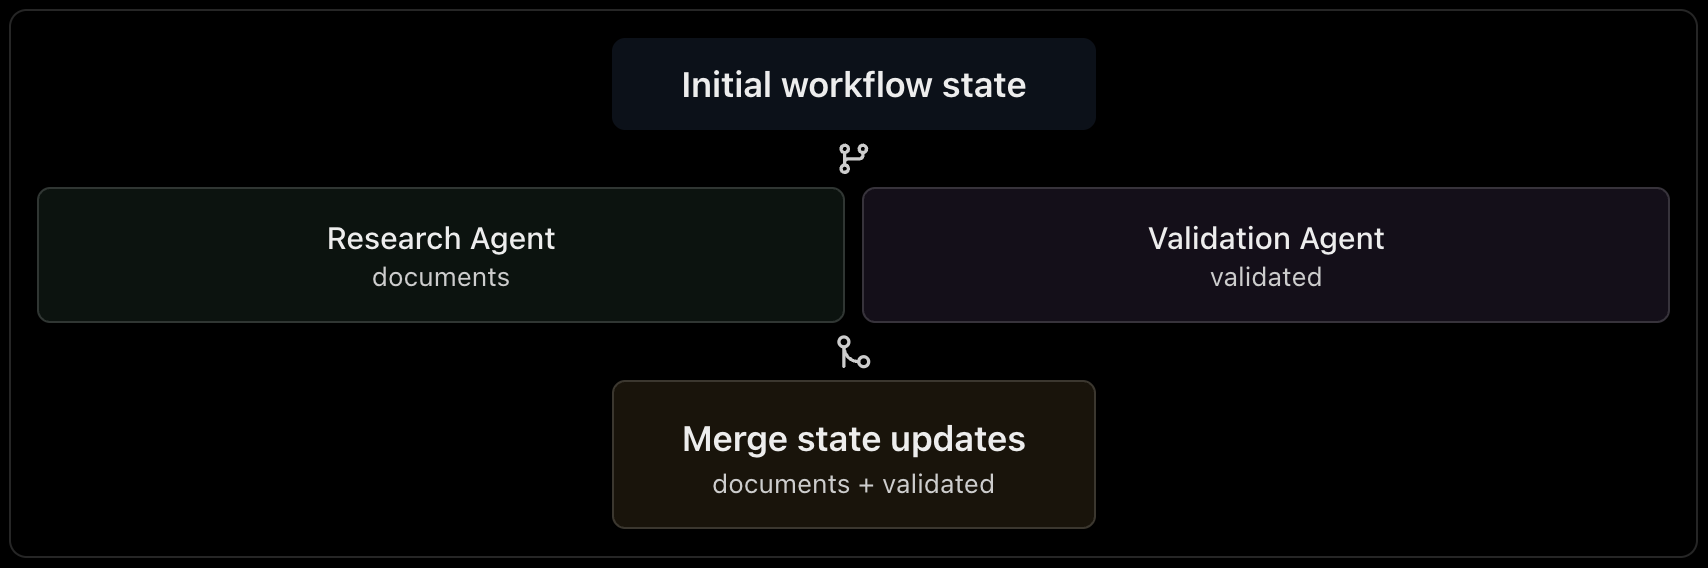

This works cleanly because the agents update different keys.

If two agents update the same key, however, you must define a conflict resolution rule. Simply using dict.update() means the later update wins, which may be incorrect.

In LangGraph, reducers can be used to combine concurrent updates to a shared state field.


In [25]:
# 4. Quick coding exercise — 5 minutes
# Consider this small multi-agent workflow

import asyncio

async def agent_a():
    return {"results": ["Document A"]}

async def agent_b():
    return {"results": ["Document B"]}

async def main():
    results = await asyncio.gather(
        agent_a(), agent_b()
    )

    state = {"results": []}

    # for result in results:
    #     state.update(result)

    for result in results:
        state["results"].extend(result["results"])

    print(state)

await main()


{'results': ['Document A', 'Document B']}


Interview Questions:

Q1. How would you manage state when three agents execute in parallel?

Have each agent produce an independent state update. Merge results through an explicit aggregation step. 
Where agents contribute to the same field, define appropriate merge semantics, such as combining lists, selecting a version, or rejecting conflicting updates.

Q2. Is asyncio.Lock sufficient for multi-agent production infrastructure?

Only when the shared state is accessed by coroutines within the same event loop and all relevant operations use the same lock. Distributed agents require coordination through durable storage, concurrency controls, or other distributed mechanisms.

Q3. How would you prevent duplicate tool executions after a retry?

Use an idempotency key or unique operation identifier, record execution outcomes in durable storage, and ensure retries do not repeat external side effects such as ticket creation or payment processing.

One Statement Summary: 

In parallel agent execution, I prefer isolated state updates with explicit merge semantics over uncontrolled shared mutable state, and I use appropriate concurrency controls when shared updates are unavoidable.


### Module 3 — State Management in Multi-Agent Workflows

Now we'll build a small Planner → Researcher → Executor workflow and progressively add state management, retries, and checkpointing.
By the end, you should be able to explain:
    1. How state flows between multiple agents.
    2. Who owns the state and who modifies it.
    3. How the orchestrator controls agent execution.
    4. What happens when an agent fails.
    5. How checkpointing and recovery work.

1. Understanding a stateful multi-agent architecture
Consider an enterprise knowledge-discovery system where a user asks:
Find the latest contractor leave policy for Sweden and prepare a summary.

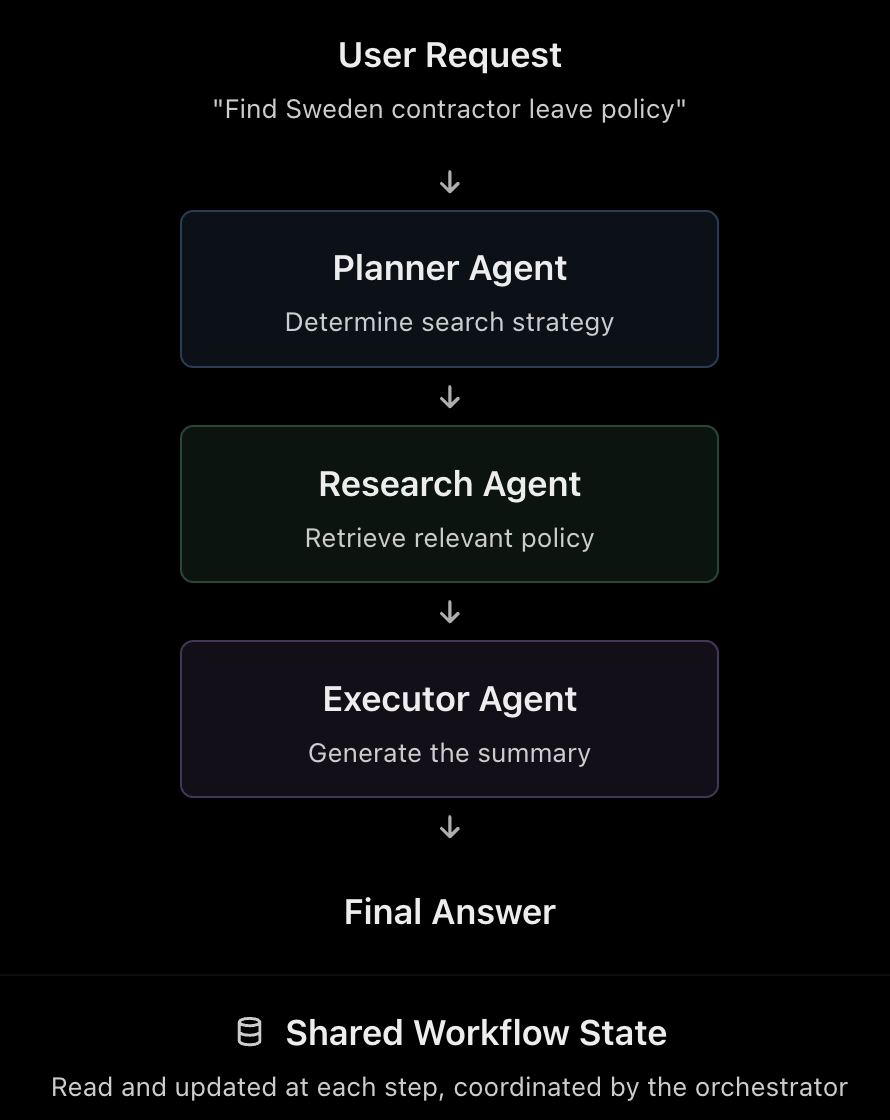



The key architectural concept:

    An agent performs a task. 

    An orchestrator controls the workflow. 
    
    State connects the execution steps.

For the following examples, our agents will be simple Python functions so that we can focus on the architecture rather than LLM APIs.

In [4]:
# Example 1 — Basic workflow with explicit state (10 minutes)

state = {
    "query": "Sweden contractor leave policy", 
    "plan": None,
    "answer": [],
     "status": "started"
    }

def planner(s):
    return {
        **s, 
        "plan": "Search contractor policies", 
        "status": "planned"
    }

def researcher(s):
    return {
        **s, 
        "documents": ["Sweden Leave Policy 2026"],
        "status": "retrieved"
    }

def executor(s):
    return {
        **s, 
        "answer": f"Summary of {s['documents'][0]}",
        "status": "completed"
    }

# orchestrator 
for agent in (planner, researcher, executor):
    state = agent(state)

print (state["answer"])
print (state["status"])

Summary of Sweden Leave Policy 2026
completed


What happens internally?

Step 1: "Planner" reads "Query" and updates "plan" and "status"
Step 2: "Researcher" reads the "plan" (conceptually) and updates with "documents" and "status"
Step 3: "Executor" reads the "documents" and generates / updates the "answer" and "status"

Note: 
1. In real world, the researcher would pass the plan to the retrieval tool 

**Interview Question**
Who owns the State?

The orchestrator owns the andcoodinates the authoritative workflow. Individual agents receive relevant state and return updates. 

This makes it easier to implement audit logs, retries, validation and recovery.

Note that LangGraph nodes commonly return state updates, while the framework manages how those updates are applied.


Excample 2 - What happens if an agent fails?

Suppose the research agent calls a document repository, but the repository is temporarily unavailable..

In [9]:
state = {
    "query": "Sweden Contractor Leave Policy",
    "status": "started",
    "retries": 0
}

def researcher(s):
    if s["retries"] == 0:
        raise ConnectionError("Document APi Unavailable")
    return {**s, "documents": ["Leave Policy 2026"]}

In [8]:
state = {
    "query": "Sweden Contractor Leave Policy",
    "status": "started",
    "retries": 0
}

def researcher(s):
    if s["retries"] == 0:
        raise ConnectionError("Document APi Unavailable")
    return {**s, "documents": ["Leave Policy 2026"]}

try:
    state = researcher(state)
except ConnectionError:
    state = {**state, "retries": state["retries"] + 1}
    state = researcher(state)

print(state["documents"])
print(state["retries"])

['Leave Policy 2026']
1


The above program raised an exception. 

Now we introduce a small orchestrator with retry logic:

In [12]:
def run_with_retry(agent, state, max_retries=2):
    for attempt in range(max_retries + 1):
        try:
            return agent({
                **state,
                "retries": attempt
            })
        except ConnectionError:
            if attempt == max_retries:
                raise

state = run_with_retry(researcher, state)

print(state["documents"])
print(state["retries"])

['Leave Policy 2026']
1


The first attempt failed. The second attempt succeeded.

Important distinction: Retry vs recovery

Retry	                            Recovery
Reattempts a failed operation	    Restores workflow execution after interruption
Often runs within the same process	May happen after a restart
Usually doesn't require persistence	Typically requires durable state
Useful for transient failures	    Useful for crash or long-running workflow recovery

Retries can be part of a recovery strategy, but the two concepts aren't identical.

Senior-level insight: Before retrying a tool that creates or modifies an external resource, consider idempotency. A network timeout doesn't guarantee that the external operation failed.

For example, a ticket creation request might have succeeded even though the response never reached the agent.

Example 3 — Checkpointing and recovery (15 minutes)

Let's say the Planner completes, but the process crashes before the Researcher begins.

Without persistence, a restarted program loses its in-memory state.

Checkpointing solves this by saving a recoverable snapshot.

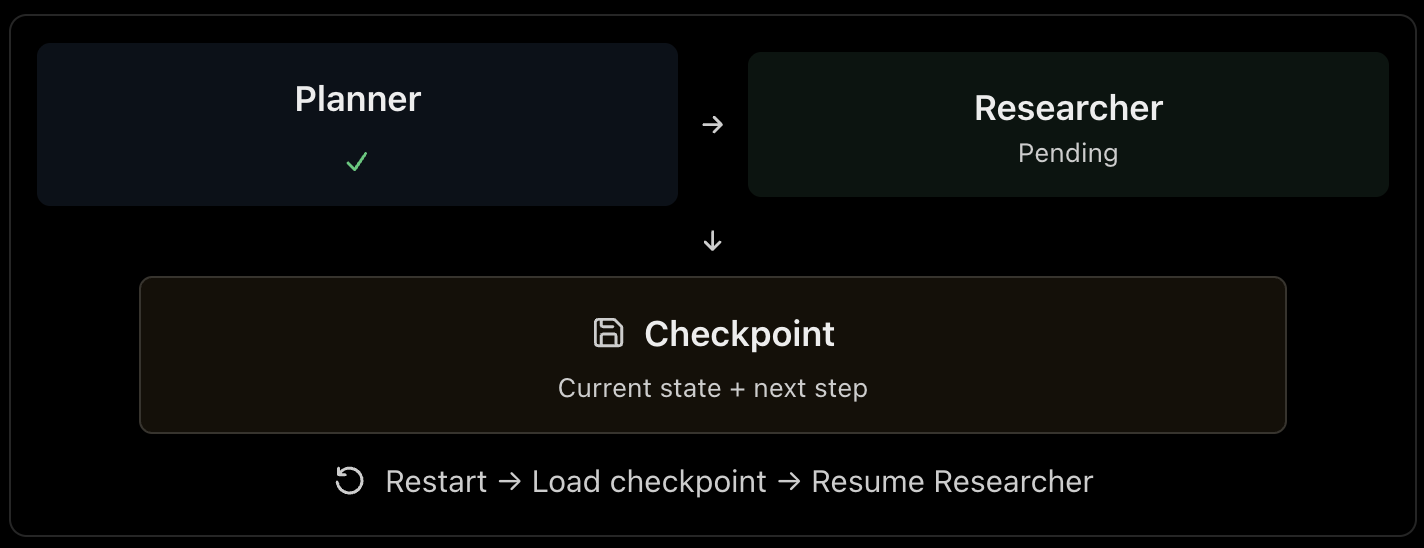


Minimal Python implementation
We'll use a JSON file as a checkpoint store.

In [ ]:
import json

def save_checkpoint(state):
    with open("checkpoint.json", "w") as f:
        json.dump(state, f)

def load_checkpoint():
    with open("checkpoint.json") as f:
        return json.load(f)

# After the Planner finishes:

state = {
    "query": "Sweden leave policy",
    "status": "started",
    "next_step": "planner"
}

state = planner(state)
state["next_step"] = "researcher"

save_checkpoint(state)

# When the process restarts:
state = load_checkpoint()

if state["next_step"] == "researcher":
    state = researcher({
        **state,
        "retry_count": 1
    })
    state["next_step"] = "executor"

    save_checkpoint(state)


In this illustration, the retry count is set to 1 solely to reuse the earlier simulated researcher. In a real system, the retry count should reflect actual attempted executions.

Also, writing JSON directly to a file is only a teaching example. A production checkpoint store needs durability, concurrency control, appropriate atomicity, and secure handling of stored data.

What must be saved in a checkpoint?
Think beyond just the user query.

Checkpoint field	                Purpose
Workflow ID	                        Identify a particular execution
Current state	                    Restore context and intermediate results
Next step	                        Know where to resume
Retry metadata	                    Apply retry policies correctly
Approval status                     Preserve human decisions
Tool execution IDs	                Help prevent duplicate external actions

For a production agentic workflow, avoid persisting credentials, secrets, or unrestricted sensitive document content in checkpoint records.

5. How state management fits into real orchestration frameworks
Let's connect this to systems relevant to your interview.
Concept	        Python example	    LangGraph   	        AWS Step Functions
State	        Dictionary	        Graph state schema	    JSON execution state
Workflow step	Python function	    Node	                Task state
Orchestrator	for loop	        Graph runtime	        State machine
Transition	    Next function call	Graph edge	            Next / Choice
Retry	        try/except loop	    Node retry policy	    Retry configuration
Persistence	    JSON checkpoint	    Checkpointer	        Service-managed execution 
                                                            state/ history
Resume	        Read next_step	    Resume from checkpoint	Workflow execution mechanisms

One nuance: Step Functions Standard executions provide durable state-machine execution, but they don't behave exactly like LangGraph's application-level checkpoint store. Their models of resumption, replay, and task boundaries differ.


6. Quick exercise — 5 minutes
Here's a deliberately incomplete workflow:

In [13]:
state = {
    "query": "Sweden policy",
    "status": "planned",
    "documents": [],
    "next_step": "researcher"
}

def researcher(s):
    return {
        **s,
        "documents": ["Policy 2026"]
    }

def executor(s):
    return {
        **s,
        "answer": f"Found {s['documents'][0]}"
    }

Your task: Complete a small orchestrator that:
- Checks next_step.
- Executes researcher if required.
- Updates next_step to "executor".
- Executes executor.
- Sets status to "completed" and next_step to None.

{
    "query": "Sweden policy",
    "status": "completed",
    "documents": ["Policy 2026"],
    "next_step": None,
    "answer": "Found Policy 2026"
}

Interview Questions

1. How do agents communicate state?

Through the orchestrator or or explicitly defined communication channels. Each agent consumes the context it needs and produces a structured result. The orchestrator applies validated updates to the workflow state.

2. What happens when an agent fails halfway through?
Use a retry polcy for recoverable failures, or restore the workflow from a durable checkpoint. External side effects reqquire additional safeguards because they may already have completed before the failure was observed.

3. How do you prevent duplicate operations during recovery?
Give external operations stable idempotency keys and persist operation status. Where the external systems supports idempotency, retries reuse the same key.. Otherwise, reconciliation or deduplication may be necessary. 

4. What if two agents update the same field?
Prefer isolated agent outputs and merge them with a defined reducer. For conflicting updates, introduce validation, version checks, or serialized ownership rather than relying on arbitrary last-writer-wins behavior. 

5. Is checkpointing enough to guarantee exactly-once execution? 
No. A crash may happen after a tool performs an action but before the checkpoint recordsx its success. Checlpointing helps with resumption, while idempotency and transactional design are needed to control duplicate side effects. 

Final interview summary

A concise explanation you can use:
In a multi-agent system, I would maintain an explicit workflow state containing the user request, intermediate outputs, execution progress, tool results, and approval status. The orchestrator controls transitions between agents, while each agent returns structured state updates. For production reliability, I would introduce retries for transient failures, durable checkpoints for recovery, and idempotency controls for external actions. For parallel agents, I would use isolated outputs and deterministic merging to avoid concurrent state conflicts.


Module 4 — LangGraph vs AWS Step Functions (45 minutes). 

We'll focus on how both systems manage state, checkpointing, conditional branching, agent loops, human-in-the-loop approval, and failure recovery, using your familiarity with AWS Step Functions and Lambda to make the comparison intuitive.

Objective: Understand how both frameworks manage state, orchestration, retries, persistence, agent loops, and human approval, and how to justify an architecture choice in an interview.


1. The architectural difference (5 minutes)
Both systems orchestrate workflows, but their emphasis differs.

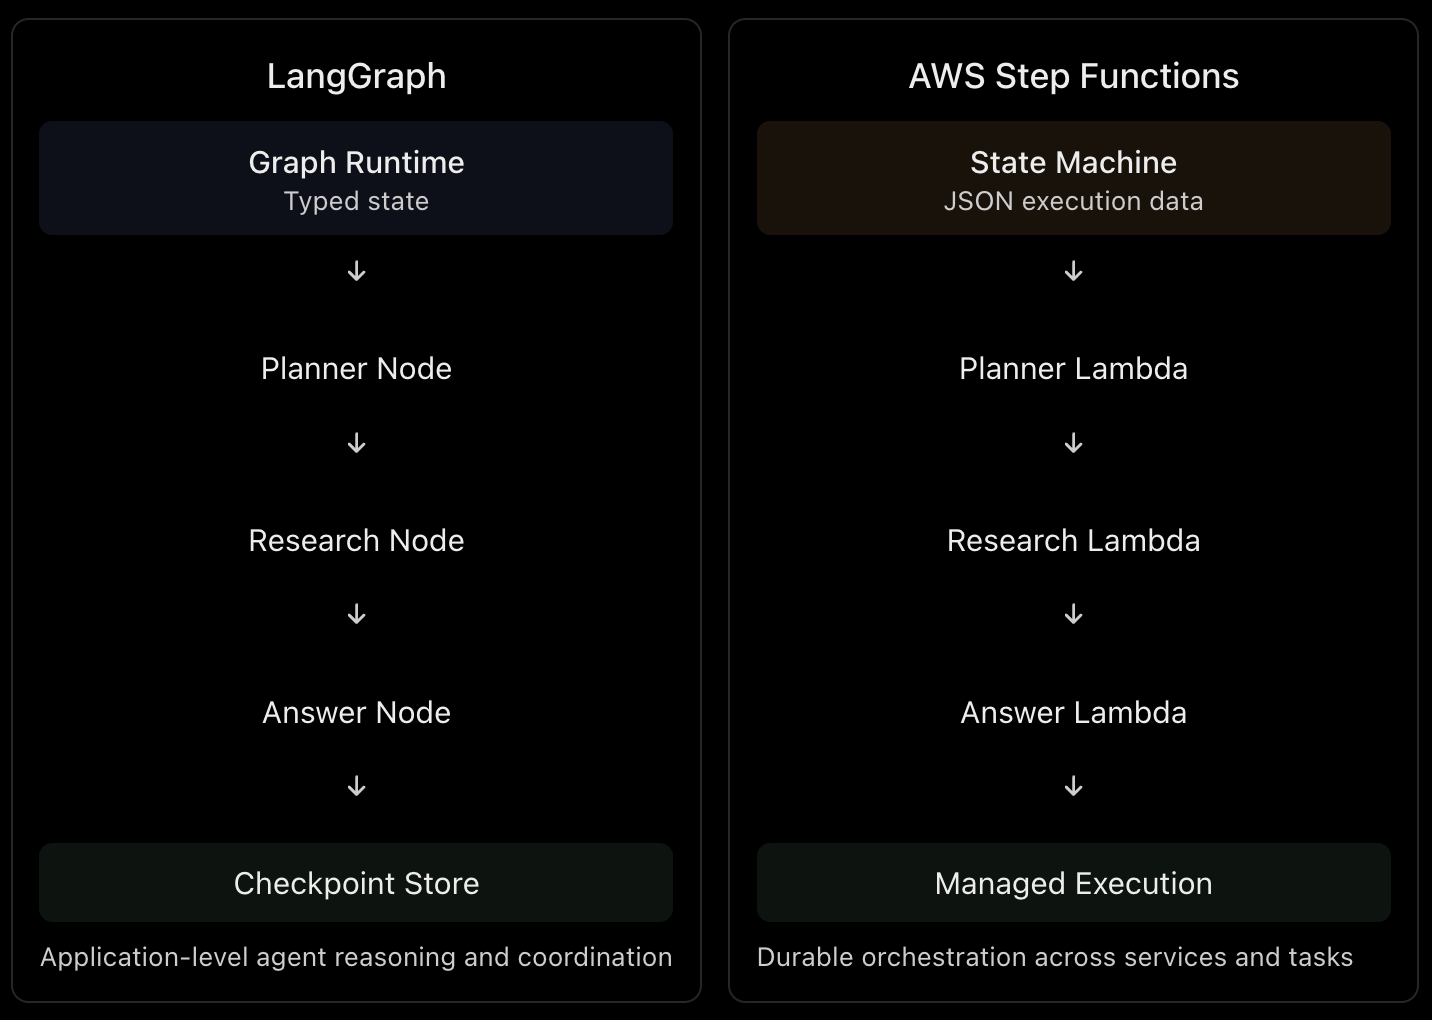

The distinction to remember:
- LangGraph: Think in terms of agents, nodes, edges, state reducers, interrupts, and checkpoints.
- Step Functions: Think in terms of states, tasks, transitions, JSON data, retries, callbacks, and managed execution history.
Neither requires an LLM. Both can orchestrate ordinary software functions.


2. State Management: LangGraph vs Step Functions (10 minutes)
Let's implement the same tiny workflow in both systems.
A. LangGraph — Python
Install the package locally with pip install langgraph.


In [15]:
from typing import TypedDict
try:
    from langgraph.graph import StateGraph, START, END  # type: ignore
except ModuleNotFoundError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "langgraph"])
    from langgraph.graph import StateGraph, START, END  # type: ignore

class AgentState(TypedDict):
    query: str
    documents: list[str]
    answer: str

def researcher(state: AgentState):
    return {"documents": ["Policy 2026"]}

def executor(state: AgentState):
    return {
        "answer": f"Found {state['documents'][0]}"
    }

builder = StateGraph(AgentState)

builder.add_node("researcher", researcher)
builder.add_node("executor", executor)

builder.add_edge(START, "researcher")
builder.add_edge("researcher", "executor")
builder.add_edge("executor", END)

graph = builder.compile()

result = graph.invoke({
    "query": "Sweden leave policy",
    "documents": [],
    "answer": ""
})

print(result["answer"])

Found Policy 2026


Notice three important things.
1. AgentState defines the fields available in the graph state.
2. Each node receives the state and returns a partial update, not necessarily the entire state.
3. LangGraph applies updates and routes execution according to the defined edges.

This is an important difference from the manual dictionaries we used in Module 3.


B. AWS Step Functions — equivalent idea

A simple Step Functions state machine can use Pass states to demonstrate how JSON moves between steps.


In [16]:
{
  "StartAt": "Researcher",
  "States": {
    "Researcher": {
      "Type": "Pass",
      "Result": {
        "documents": ["Policy 2026"]
      },
      "ResultPath": "$.research",
      "Next": "Executor"
    },
    "Executor": {
      "Type": "Succeed"
    }
  }
}

{'StartAt': 'Researcher',
 'States': {'Researcher': {'Type': 'Pass',
   'Result': {'documents': ['Policy 2026']},
   'ResultPath': '$.research',
   'Next': 'Executor'},
  'Executor': {'Type': 'Succeed'}}}

Input: 

In [ ]:
{
  "query": "Sweden leave policy"
}

State reaching Executor:

In [ ]:
{
  "query": "Sweden leave policy",
  "research": {
    "documents": ["Policy 2026"]
  }
}

In a real workflow, you would replace the Pass states with Lambda tasks or service integrations.

The important field here is ResultPath.

"ResultPath": "$.research" stores the task output under research while preserving the other input fields. Without an explicit ResultPath, a JSONPath-based task normally replaces its input with the task result.


State management mapping

LangGraph	                AWS Step Functions
AgentState	                JSON execution data
Node function	            Task / Lambda
Node returns an update	    Task returns result
State reducer	            Result mapping, transformations, explicit merging
Graph edge	                Next
Conditional edge	        Choice
Checkpointer	            Managed execution state, plus external storage when required

Interview takeaway: LangGraph offers a typed, application-level state model with reducers. Step Functions manages JSON execution data flowing between service tasks.

3. Conditional routing and agent loops (5 minutes)

Consider this workflow:

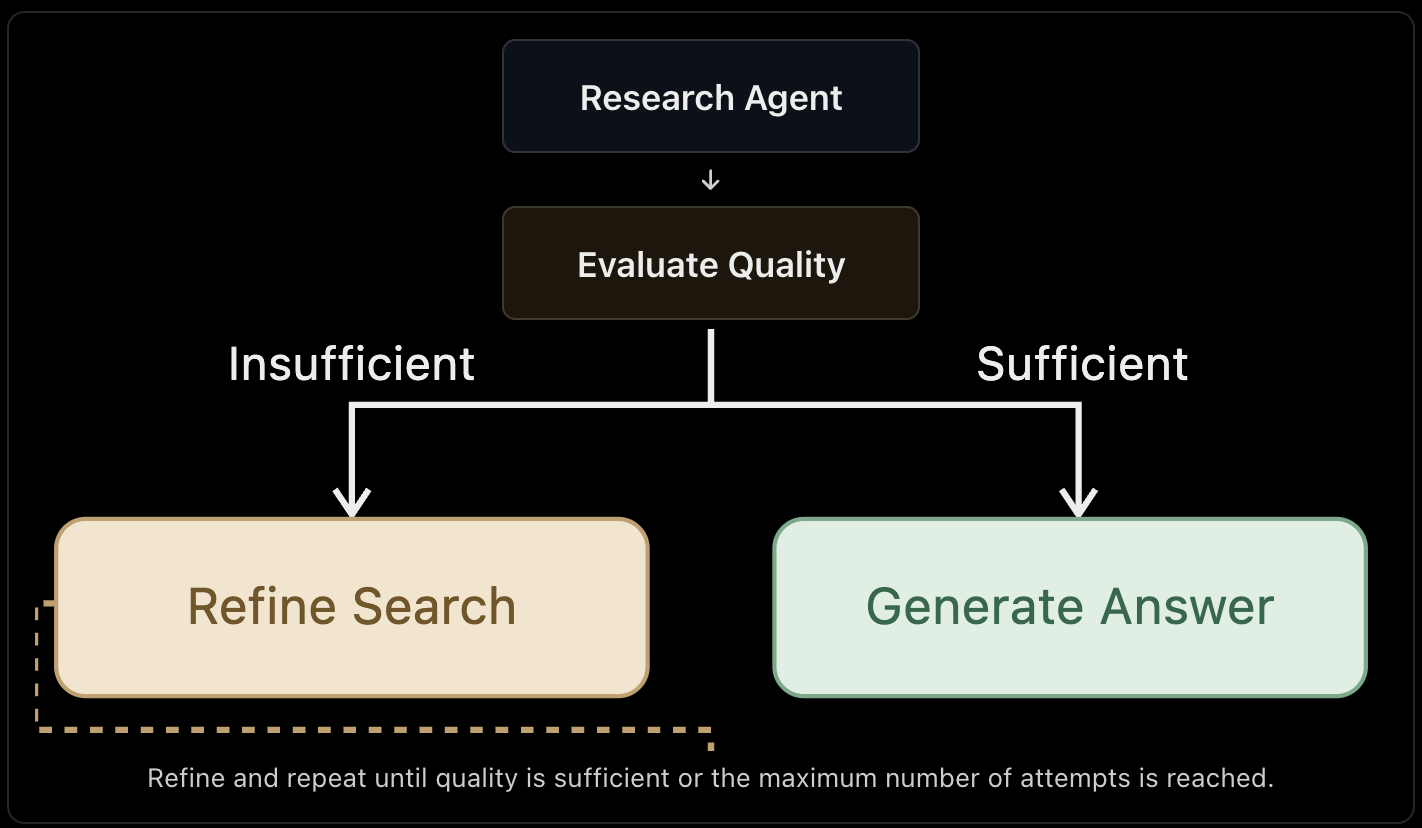


In LangGraph, conditional edges decide which node executes next.

In Step Functions, Choice states make equivalent routing decisions, often using outputs or status flags from Lambda functions.

Both can implement loops. But a loop involving complex LLM reasoning, tool selection, and intermediate agent decisions is often more convenient to express inside LangGraph.

Senior-level point: Always define termination conditions such as max_iterations, deadlines, or token/cost budgets. Otherwise, an agent loop may keep calling tools indefinitely.


4. Checkpointing, retries and recovery (10 minutes)

This is arguably the most important part for an AI Infrastructure interview.
LangGraph: Checkpointing
LangGraph has a persistence mechanism called a checkpointer. It saves graph state at execution boundaries so that a workflow can be resumed or inspected later. 

Example of enabling an in-memory checkpointer:

In [17]:
from langgraph.checkpoint.memory import InMemorySaver

checkpointer = InMemorySaver()

graph = builder.compile(
    checkpointer=checkpointer
)

config = {
    "configurable": {
        "thread_id": "workflow-123"
    }
}

result = graph.invoke(
    {
        "query": "Sweden leave policy",
        "documents": [],
        "answer": ""
    },
    config=config
)

snapshot = graph.get_state(config)
print(snapshot.values["answer"])

Found Policy 2026


The thread_id identifies the sequence of checkpoints associated with that workflow.

Important: InMemorySaver is useful for learning and testing, but won't survive a process restart. For production recovery, use a durable checkpointer, such as a suitable database-backed implementation.

AWS Step Functions: Durable execution

For a Standard workflow, Step Functions manages execution progress and history. You don't have to write your own JSON checkpoint after every Lambda invocation.

AWS also supports redrive, which can restart eligible unsuccessful Standard workflow executions from the failed step, preserving successful preceding steps

Compare a crash after the Research Agent has finished:

Situation	                LangGraph	                            Step Functions Standard
Research completed	        Saved in checkpoint, if configured	    Successful task recorded
Next task fails	            Can resume using persisted graph state	Retry or redrive supported
Process/container crashes	Requires durable checkpointer and resumed invocation	AWS continues managing execution
Inspect history	            Checkpoints, traces	                    Execution history and logs
Re-execute earlier steps	Depends on recovery boundary	        Redrive preserves successfully completed steps


Neither system automatically makes external side effects exactly-once.

A production scenario worth remembering: A tool creates a Jira ticket successfully, but the network connection times out before the agent receives confirmation. A retry could create a duplicate ticket. The solution is idempotency and reconciliation, not merely checkpointing.


5. Human-in-the-loop approval (5 minutes)

Suppose your agent must file an employee's leave request, but should only do so after explicit approval.

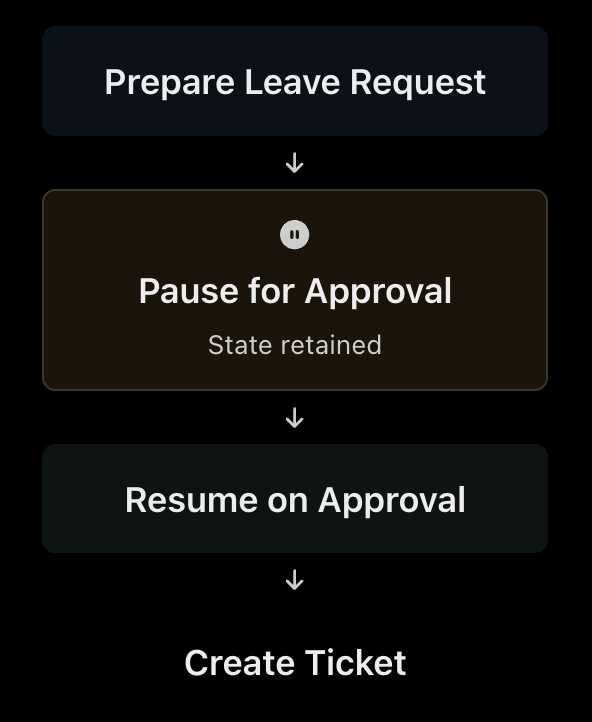

LangGraph: Use an interrupt to pause execution, persist graph state, and resume with an approval decision using Command(resume=...). 

AWS Step Functions: In a Standard workflow, use a task-token callback integration. The workflow can wait until an external application returns the token through SendTaskSuccess or SendTaskFailure. 

Security considerations apply to both: authenticate the approver, enforce authorization, record the approval decision, and prevent reuse of approvals.

Interview question

If approval takes three days, which framework would you choose?

Both can support this scenario. If the broader process is an AWS service workflow with long-running approvals, Step Functions Standard is a natural fit. If the pause is part of a dynamic conversational agent's reasoning, LangGraph's interrupts may be easier to work with.

The decision depends on the overall architecture, not merely the three-day delay.

6. When would you choose LangGraph, Step Functions, or both? (5 minutes)

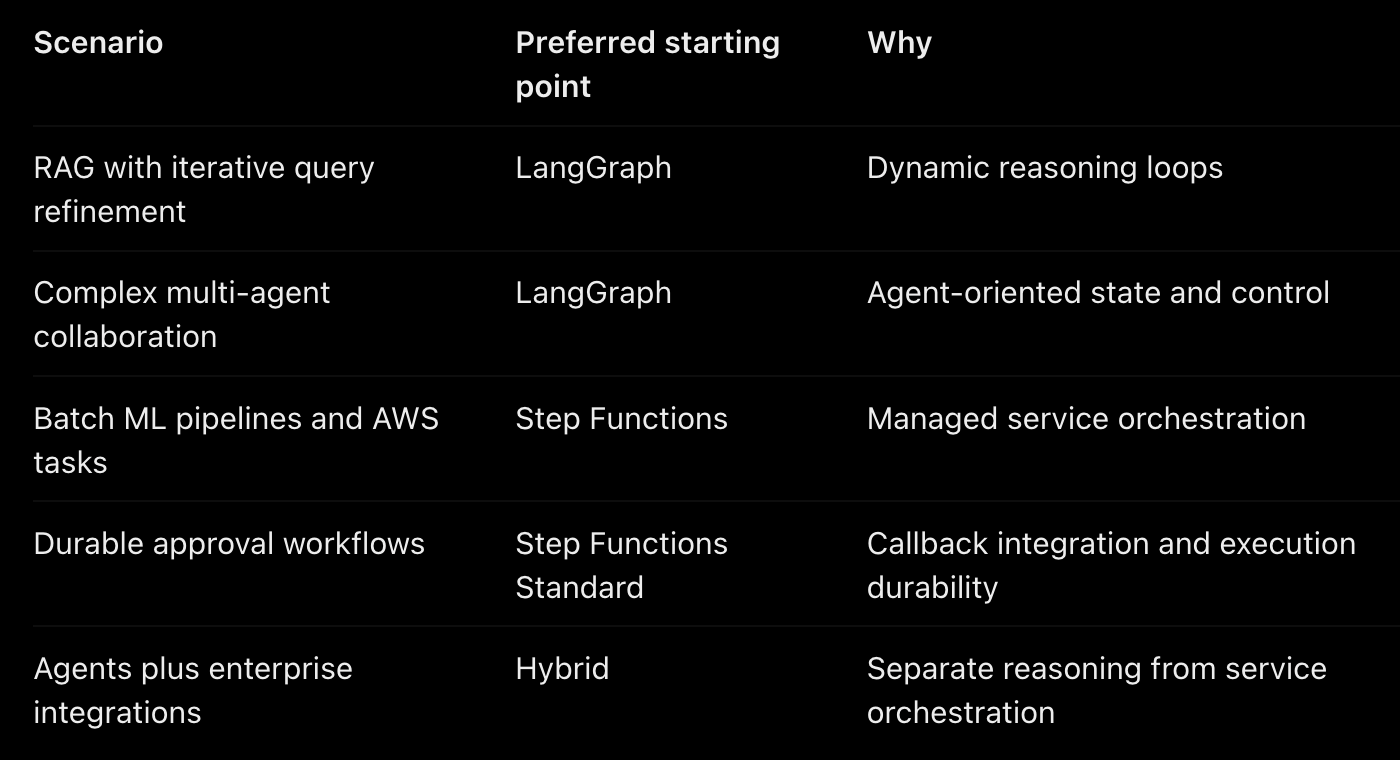


Hybrid architecture: Especially relevant to your experience

Imagine your enterprise feature-discovery agent, retrieving metadata from Alation, Snowflake and GitHub, creating a proposed feature definition, and raising a change request.

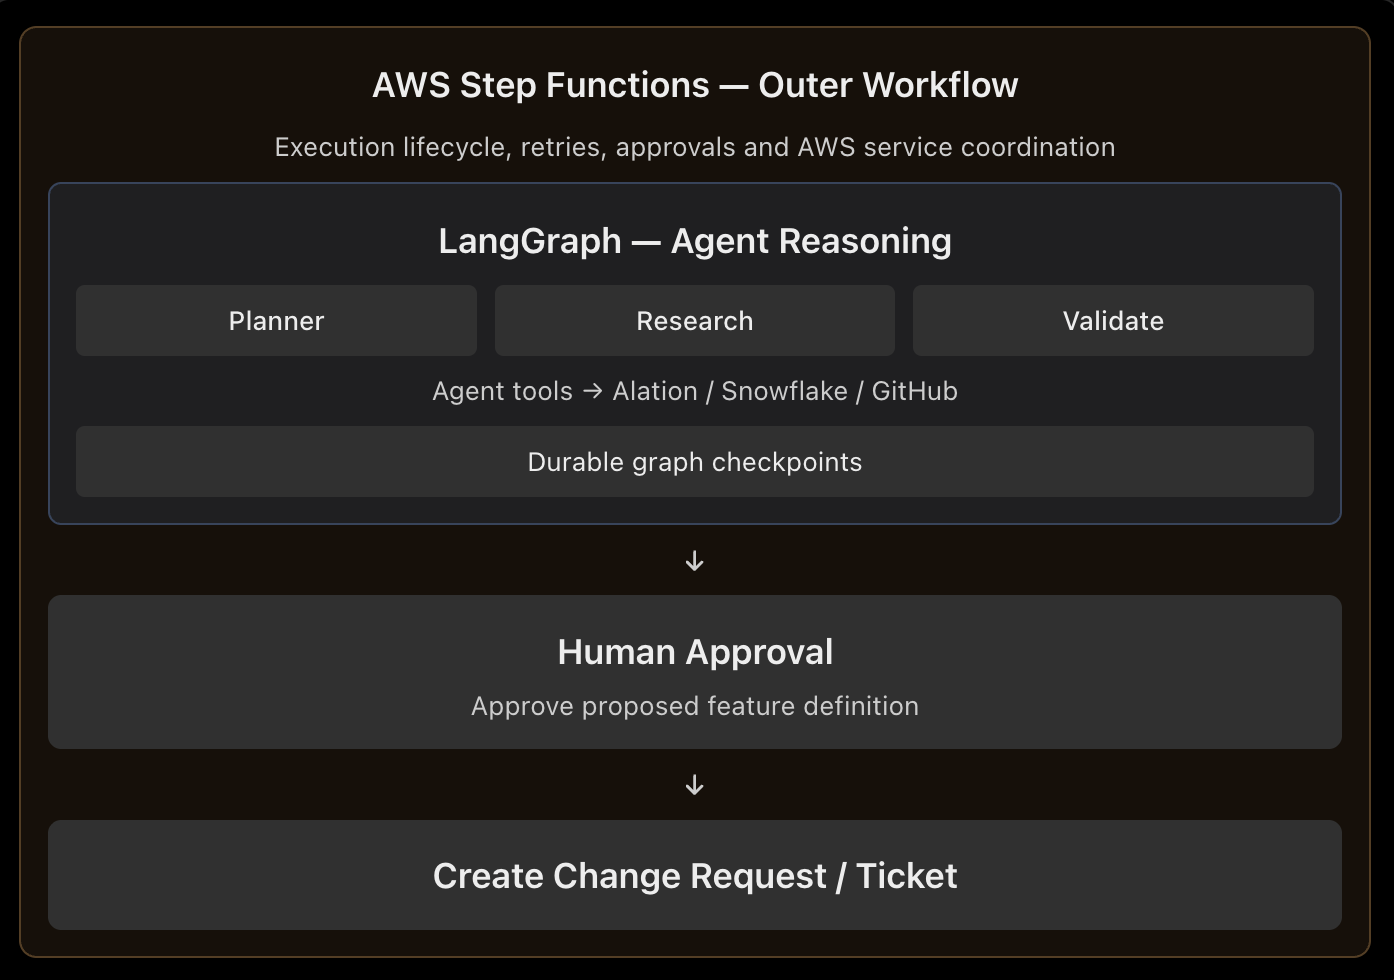

In this architecture:
    - Step Functions manages the overall business workflow.
    - LangGraph coordinates internal agent reasoning and iterative searches.
    - Agents interact with enterprise retrieval tools.
    - Durable checkpoints preserve agent progress when required.
    - Step Functions resumes the wider workflow when the agent run completes or returns a persisted job reference.
    - External actions remain protected by approvals and idempotency controls.

One operational consideration: if LangGraph runs as a long-running service, Step Functions should invoke it using an appropriate asynchronous job or callback pattern instead of keeping a Lambda invocation open indefinitely.

This hybrid architecture is a defensible choice, not a requirement. For a smaller application, one orchestration layer may be simpler.


7. Quick interview exercise — 5 minutes
A RAG agent has the following state:

In [ ]:
state = {
    "query": "Find current contractor policy",
    "documents": [],
    "quality_score": 0.0,
    "attempts": 0
}

The Research Agent retrieves documents, and an Evaluator produces a quality_score between 0 and 1.

Requirement: If the score is below 0.8, search again, but allow no more than three retrieval attempts.

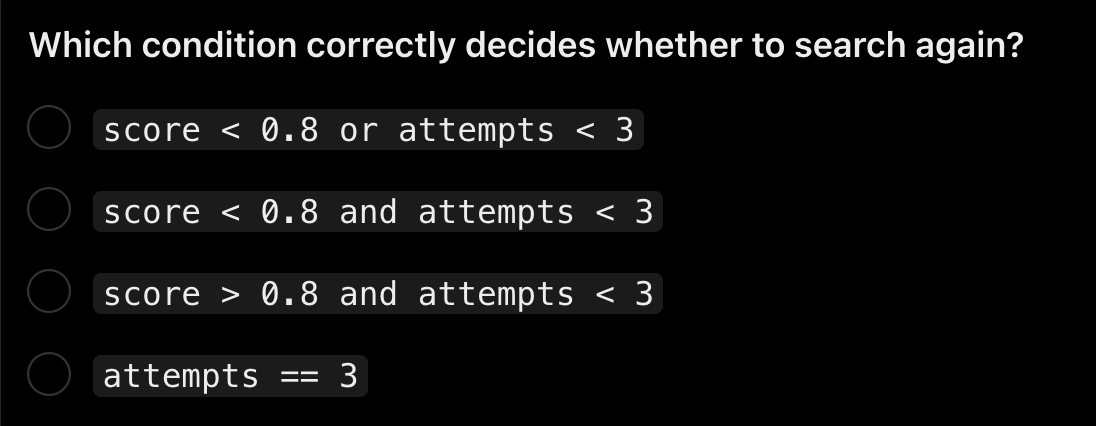

Answer: Both conditions must be true. The quality must be insufficient, and the retrieval-attempt limit must not have been reached.

In [ ]:
def should_retry(state):
    return (
        state["quality_score"] < 0.8
        and state["attempts"] < 3
    )

8. Five Questions to expect in the interview 

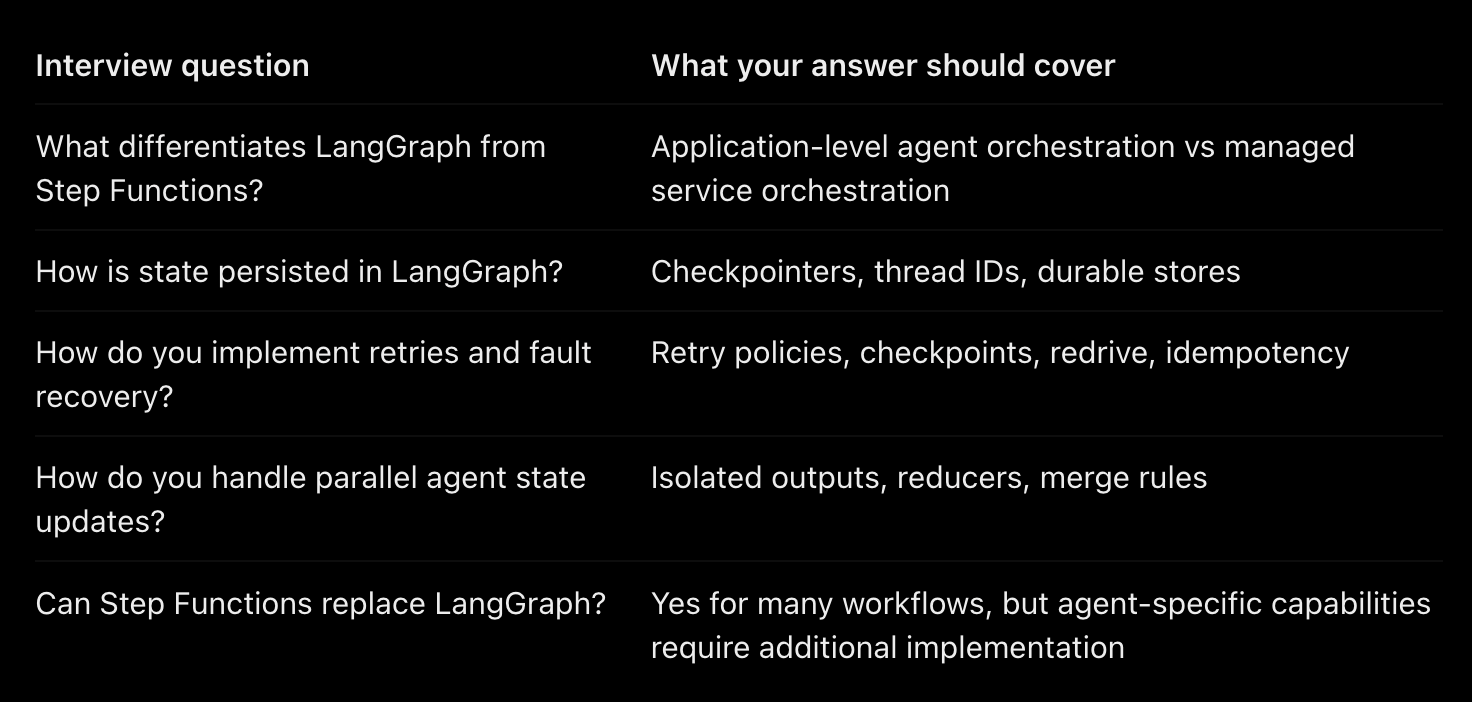

Summary 

I've used AWS Step Functions and Lambda for orchestrating ML and data workflows, so I view LangGraph as solving a related problem at the agent execution level.

Step Functions is particularly effective for durable service orchestration, retries, long-running jobs and enterprise integrations. LangGraph provides a graph-based execution model where agents share structured state, support conditional routing, reasoning loops and checkpointing.

For an enterprise agentic platform, I would evaluate a hybrid approach: LangGraph for dynamic reasoning and tool coordination, and Step Functions for the broader business workflow, approvals and service orchestration. I'd ensure both layers have clear state ownership, recovery boundaries, observability and idempotency controls.

Module 5 — Senior AI Engineer Interview Scenarios

We've covered state fundamentals, concurrency, multi-agent orchestration, LangGraph, and AWS Step Functions.

This final module is about applying those concepts to production AI systems and explaining your decisions convincingly in a Senior AI Engineer interview.

Our focus is on the questions a hiring engineer might ask to distinguish someone who understands agentic workflows from someone who has only built a demonstration.


1. The five dimensions of production-grade state management (5 minutes)
Whenever you're asked to design an agentic workflow, consider these five dimensions.

1. State Ownersghip: Who reads and writes state?

2. Concurrency: What if agents execute in parallel?

3. Durability: What survives a failure?

4. Consistency: How are conflicts resolved?

5. Observability: Can you trace state transitins, failures, tool calls and recovery decisions?


2. Six production scenarios and interview answers (20 minutes)

Scenario 1 — An agent fails after creating a ticket

Interviewer: Your AI agent creates a ServiceNow ticket. The API successfully creates the ticket, but the response times out. The workflow retries. How do you prevent duplicate tickets?

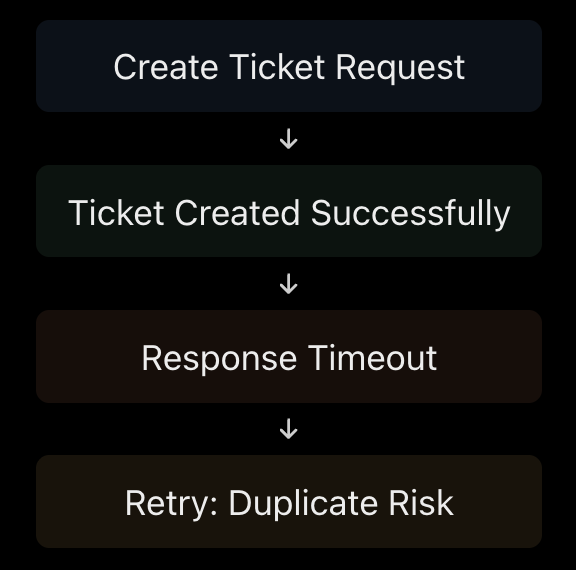

I'd distinguish execution failure from business-operation failure. A timeout doesn't necessarily mean the ticket wasn't created.

I'd assign a stable idempotency key to the operation, persist its status, and reuse the same key on retries. If the ticket API supports idempotency, it can return the previously created result. Otherwise, I'd reconcile against the external ticket system using a unique correlation identifier before retrying.

Checkpointing helps recovery, but it doesn't by itself prevent duplicate side effects.

Critical concept: At-least-once execution + idempotent business operations.

Be prepared to explain that exactly-once side effects cannot simply be assumed across a network boundary.

Scenario 2 — Three agents execute in parallel

Interviewer: A Research Agent, Policy Validation Agent, and Compliance Agent execute simultaneously. Each produces updates to the same workflow. How would you manage the state?

Answer: 

I would prefer isolated outputs for each agent rather than allowing uncontrolled modifications to a shared dictionary.

The orchestrator would collect the results and merge them through explicit rules. For independent fields, merging is straightforward. For the same field, I'd define reducers, ownership rules, or conflict resolution. For a shared database, I'd use transactions or optimistic concurrency where appropriate.

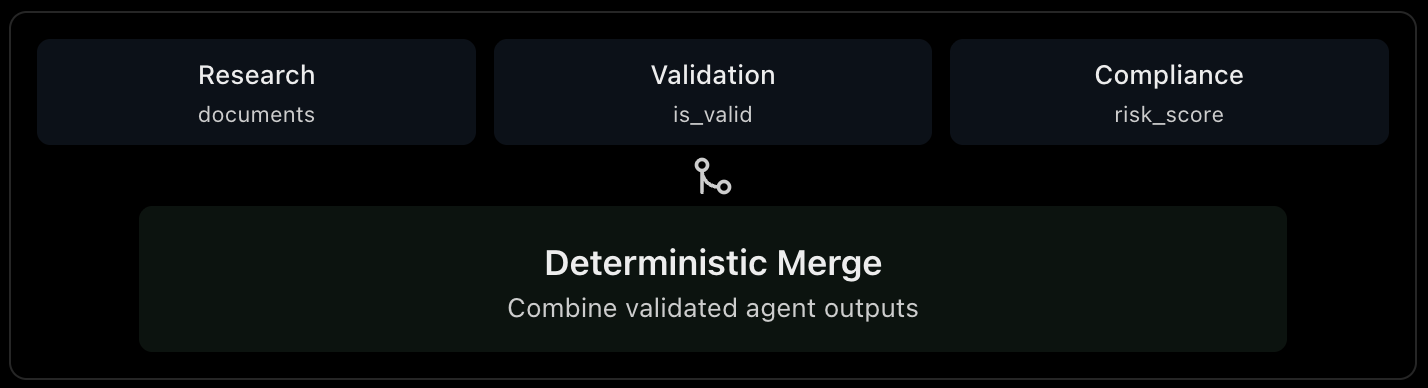

Follow-up: What if two agents return conflicting risk_score values?

Don't average them automatically. First define what the scores mean, whether they are comparable, which agent has authority, and whether a conflict requires escalation.


Scenario 3 — Human approval after three days

Interviewer: An agent prepares an employee leave request, but an HR manager takes three days to approve it. How would you maintain the workflow state?

Interview-ready answer:
I'd persist the workflow state and move it into a waiting-for-approval condition. The state would contain the workflow ID, the proposed action, approval status, and sufficient context to resume.

Once the approval arrives, I'd authenticate the approver, validate that the decision applies to the current request version, and resume execution. I'd avoid keeping a compute process running while waiting.

This maps naturally to LangGraph interrupts or AWS Step Functions Standard callback patterns.

Important follow-up: What happens if the user changes the request while it is awaiting approval?

The approval should apply to a specific immutable request version. If the request changes materially, require a new approval rather than executing a modified action under an old authorization.

Scenario 4 — One agent crashes, another has completed

Interviewer: A five-step workflow crashes at Step 4. How would you resume it without redoing everything?

Interview-ready answer:
I'd use durable checkpoints at well-defined execution boundaries. The checkpoint would preserve the workflow ID, state, completed steps, next executable step, and relevant tool-operation identifiers.

On recovery, the orchestrator loads the checkpoint and resumes from the appropriate boundary. Before repeating an externally visible action, it checks whether the action already completed.

With LangGraph I'd use a durable checkpointer. With Step Functions Standard I'd rely on managed execution state and appropriate retry or redrive behavior.

Key distinction: Workflow resumption is not the same as making every individual tool call exactly-once.

Scenario 5 — Scaling to 10,000 concurrent conversations

Interviewer: Your agentic application currently supports 100 users. Tomorrow it must support 10,000 concurrent conversations. What changes in state management?

Asnwer:

First, I would ensure state isolation using tenant IDs, user IDs, and conversation or workflow IDs.

I'd move durable execution state out of process-local memory into a suitable shared store, then use stateless application workers where practical. I'd introduce version checks for concurrent updates, retention policies, and secure access controls.

I'd also minimize large objects in workflow state, storing document references rather than entire retrieved documents when appropriate. Finally, I'd load-test the state store and measure checkpoint latency, conflict rates, and recovery performance.

Notice this answer demonstrates both application architecture and AI infrastructure concerns.

The database choice depends on access patterns, consistency requirements, throughput, and framework compatibility. Redis can be useful for ephemeral session state or caching, but a cache alone isn't necessarily the right durable checkpoint store.

Scenario 6 — A new deployment changes the state schema

Interviewer: Your production agents currently store state using schema version 1. You deploy a new agent implementation with schema version 2 while thousands of workflows are still running. What happens?

This is a particularly useful Senior/Staff-level question.

Suppose the old state contains:

In [ ]:
state_v1 = {
    "workflow_id": "123",
    "status": "running"
}

The new code requires:

In [ ]:
state_v2 = {
    "workflow_id": "123",
    "status": "running",
    "schema_version": 2,
    "retry_count": 0
}

Interview-ready answer:

I'd treat workflow state as a versioned contract. Existing checkpoints might not be compatible with the new application code.
I'd introduce explicit schema versions, validate state on loading, and implement migrations for compatible changes. For incompatible execution changes, I might keep older workflow versions running until completion rather than forcing migration.
I'd test recovery from old checkpoints before deploying the new runtime.

This demonstrates an understanding of long-running workflow lifecycle management, not just Python dictionaries.

Observability — what would you monitor? (5 minutes)

When a system fails, you need to know which agent ran, what state it received, what changed, and whether the next action was executed.

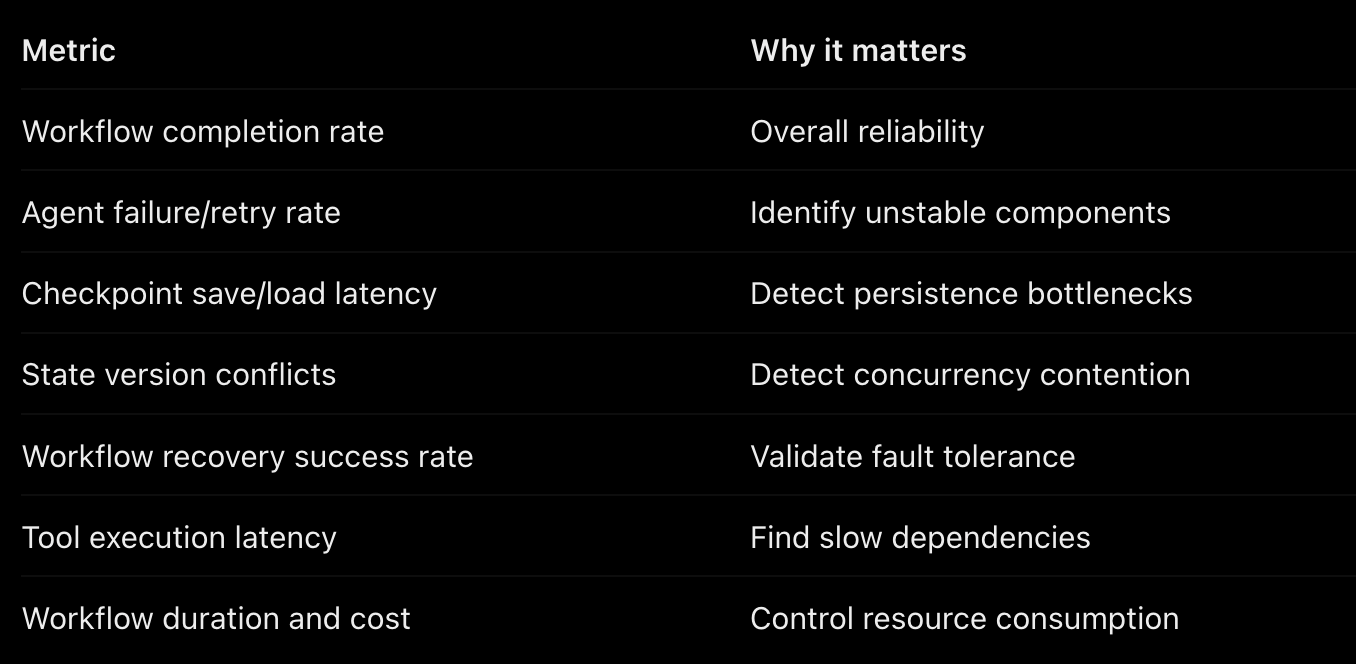

For tracing, capture a workflow ID, agent/node name, execution attempt, state version, tool call ID, duration, and outcome. 

Avoid logging credentials, unredacted sensitive data, or complete private documents simply to make debugging easier.

A strong interview statement is:

I want to trace state transitions, not just LLM prompts and responses. In production, I need to know what changed between steps and why the orchestrator made a particular decision.

Final architecture exercise (5 minutes)

Here is a small scenario resembling a genuine agentic infrastructure design discussion.
Problem: An enterprise policy agent has three workers: Researcher, Validator, and Ticket Creator.

The Researcher retrieves current policy documents. The Validator checks whether the policy applies to the user's country and employment type. The Ticket Creator submits a request only after the user approves.

Your workflow must support concurrency, durability, security, and crash recovery.

Think through these four questions before revealing the answer:
1. What fields belong in the workflow state?
2. Which stages can execute in parallel?
3. Where would you create checkpoints?
4. How would you prevent duplicate ticket creation?

In [ ]:
# Suggested Workflow state:

state = {
    "workflow_id": "wf-123",
    "user_id": "user-42",
    "query": "Sweden contractor leave",
    "documents": [],
    "validation": None,
    "approval": "pending",
    "ticket_id": None,
    "next_step": "research",
    "schema_version": 1
}

2. Parallelism

Independent document searches can execute in parallel. Validation requiring retrieved evidence must wait for the relevant search results. Ticket creation must wait for both successful validation and approval.

3. Checkpoints

Save durable state after retrieval/validation, before waiting for approval, and after ticket completion. More granular checkpointing may be appropriate for expensive or non-repeatable steps.

4. Idempotency

Generate a stable operation identifier before calling the ticket API. Persist the identifier and use it for deduplication or reconciliation during retries.

90-second architecture explanation

In an agentic workflow, I treat state management as a core orchestration responsibility rather than simply passing a dictionary between agents.

I start by defining a structured state schema containing execution context, intermediate results, task progress, approvals and recovery metadata.
Each agent receives the relevant state and returns a structured update. For parallel agents, 

I'd prefer isolated outputs with deterministic merging, rather than uncontrolled shared mutable state.

To make the workflow production-ready, I'd add durable checkpointing, retry policies, and idempotency controls for external tool actions. For sensitive enterprise workflows, I'd also enforce user and tenant isolation, authorization checks, and approval boundaries.

LangGraph would be useful for dynamic agent reasoning loops, whereas Step Functions would be useful for broader durable AWS service orchestration. I'd choose or combine them based on the workflow's complexity and operational requirements.

Finally, I'd instrument state transitions and tool executions so that failures can be diagnosed and workflows can be recovered safely.